# ITCC508 Lab Exercise PT-F2 — Chunking Experiment

**Mark Emmanuel P. Sagarino** · College of Computer Studies, Jose Rizal University

---

Part 1 prepared the dataset, the test questions and the prompt. This notebook runs the controlled
experiment those preparations were for: **which chunk size and overlap retrieves the required
evidence best** for this corpus.

### What is held constant

Dataset, embedding model, vector store type, retrieval depth, test questions, relevance criteria,
language model and prompt. Only `CHUNK_SIZE` and `CHUNK_OVERLAP` vary, so any difference in the
metrics is attributable to the chunking.

### What is measured

| Metric | Question it answers |
|---|---|
| Precision@3 | Of the three chunks returned, how many were actually useful? |
| Recall@3 | How much of the evidence a question needs was returned? |
| MRR@3 | How near the top did the first useful chunk appear? |

### Why Part 1 made this necessary

The baseline configuration retrieved only one of the three passages the hardest question requires.
The diagnostic measured where the other two sat: one at rank 4, one at rank 11. A passage ranked
fourth is one place outside the scored depth and may well be recoverable with different chunking.
That is the hypothesis this experiment tests.

## 1. Install the libraries

Identical to Part 1, with the addition of `matplotlib` for the comparison chart required by Step 9.

In [1]:
!pip install -q faiss-cpu sentence-transformers pypdf pandas openpyxl matplotlib

print("Libraries installed.")

Libraries installed.


## 2. Imports

`time` is new: Step 8 asks the recommendation to weigh efficiency, so indexing time, retrieval
latency and index size are recorded for every configuration rather than estimated afterwards.

In [2]:
from google.colab import files
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer

import faiss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import re
import os
import time
import json

from openpyxl.styles import Font, PatternFill, Alignment

print("Imports ready.")

Imports ready.


## 3. Settings held constant across every configuration

These are the controls. Step 3 of the exercise requires that each configuration use the same
document, the same embedding model and the same retrieval settings; fixing them in one cell makes
that auditable rather than assumed.

`TOP_K` stays at 3 because the metrics are defined at 3. Changing it would redefine the
measurement rather than test the system.

In [3]:
EMBEDDING_MODEL_NAME = "all-MiniLM-L6-v2"
TOP_K = 3
PDF_NAME = "Sagarino_PT-F1_Corpus.pdf"

print("Embedding model :", EMBEDDING_MODEL_NAME)
print("Retrieval depth :", TOP_K)
print("Dataset         :", PDF_NAME)

Embedding model : all-MiniLM-L6-v2
Retrieval depth : 3
Dataset         : Sagarino_PT-F1_Corpus.pdf


## 4. Load the dataset

The same PDF submitted for Part 1: a 17-page consolidation of Republic Act No. 7394 (Consumer
Act), No. 8792 (E-Commerce Act), No. 10642 (Philippine Lemon Law), No. 11967 (Internet
Transactions Act) and the Department of Trade and Industry's published consumer guidance.

Using the identical file matters. A corpus edited between configurations would invalidate every
comparison in this notebook.

In [4]:
if os.path.exists(PDF_NAME):
    pdf_file = PDF_NAME
    print("Using the PDF already present in this session.")
else:
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No file was uploaded.")
    pdf_file = next(iter(uploaded.keys()))

if not pdf_file.lower().endswith(".pdf"):
    raise ValueError("The uploaded file is not a PDF.")

print("Dataset:", pdf_file, "|", round(os.path.getsize(pdf_file) / 1024, 1), "KB")

Saving Sagarino_PT-F1_Corpus.pdf to Sagarino_PT-F1_Corpus.pdf
Dataset: Sagarino_PT-F1_Corpus.pdf | 50.1 KB


## 5. Extract the text once

The PDF is parsed a single time and the page texts are reused by all twelve configurations. Only
the chunking of that text differs between runs, which removes extraction variability as a possible
explanation for any difference in the results.

In [5]:
reader = PdfReader(pdf_file)

pages = []
for page_number, page in enumerate(reader.pages, start=1):
    text = page.extract_text()
    if text:
        text = re.sub(r"\s+", " ", text).strip()
        if text:
            pages.append({"page": page_number, "text": text})

if not pages:
    raise RuntimeError("No extractable text. The PDF may be scanned images.")

lengths = [len(p["text"]) for p in pages]
print("Pages in file         :", len(reader.pages))
print("Pages carrying text   :", len(pages))
print("Characters per page   : min", min(lengths),
      "| mean", round(np.mean(lengths)), "| max", max(lengths))
print("Total characters      :", sum(lengths))

Pages in file         : 17
Pages carrying text   : 17
Characters per page   : min 409 | mean 3580 | max 5107
Total characters      : 60860


## 6. The chunker

The function from Part 1, unchanged, so that the experiment measures the behaviour of the provided
implementation rather than of a replacement for it.

One property governs everything below: **chunking restarts at offset 0 on every page.** A page
break is therefore a hard chunk boundary at every setting, and overlap never bridges two pages. A
question whose evidence straddles a page break can never have both halves in one chunk, no matter
how large the chunks are. This matters here, because Section 24 of the Internet Transactions Act
spans pages 13 and 14, and one of the test questions needs both halves.

In [6]:
def create_chunks(pages, chunk_size, chunk_overlap):
    """
    Split each page into character-based chunks.

    Chunking is performed independently for each page. Overlap is maintained
    between consecutive chunks from the same page, never across pages.
    """
    chunks = []
    chunk_id = 0
    step_size = chunk_size - chunk_overlap

    for page_data in pages:
        page_number = page_data["page"]
        page_text = page_data["text"]
        start = 0

        while start < len(page_text):
            chunk_text = page_text[start:start + chunk_size].strip()
            if chunk_text:
                chunks.append({
                    "chunk_id": chunk_id,
                    "page": page_number,
                    "text": chunk_text
                })
                chunk_id += 1
            start += step_size

    return chunks


print("Chunker ready.")

Chunker ready.


## 7. The test set — nine questions, three per difficulty level

Step 4 requires at least nine questions, three at each level. Part 1 supplied three; six were
added here and each new one was verified against the corpus before the experiment began, exactly
as the earlier three were.

| Level | Definition used | Questions |
|---|---|---|
| Easy | one explicit fact in a single passage | E1, E2, E3 |
| Average | interpretation, or two closely related facts | A1, A2, A3 |
| Difficult | several passages, cross-statute reasoning, or an exclusion that must be recognised | D1, D2, D3 |

**Difficulty comes from the evidence required, not from vague wording.** Every question below is
fully answerable from the corpus. D2 and D3 are difficult because they are answered by *exclusions*
in two different statutes — the sort of question that defeats a retriever matching on surface
similarity, because the words that would settle the matter are the ones the question does not use.

A tenth item, G1, is a guardrail check with no supporting evidence in the corpus. It is excluded
from the retrieval metrics, which are undefined when no relevant chunk exists, and is reported
separately.

In [7]:
TEST_QUESTIONS = [
    # ---------------- EASY ----------------
    {"id": "E1", "difficulty": "Easy",
     "question": ("Under the Philippine Lemon Law, how many separate repair attempts for the "
                  "same complaint must fail before a consumer may invoke their rights?"),
     "expected_answer": "Four (4) separate repair attempts.",
     "source": "RA 10642, Sec. 5 (p. 10)"},

    {"id": "E2", "difficulty": "Easy",
     "question": "What is the Lemon Law rights period for a brand new motor vehicle?",
     "expected_answer": "Twelve (12) months from original delivery, or the first twenty thousand "
                        "(20,000) kilometres of operation, whichever comes first.",
     "source": "RA 10642, Sec. 3 (h) and Sec. 4 (p. 9)"},

    {"id": "E3", "difficulty": "Easy",
     "question": ("For how long must service firms guarantee their workmanship and the "
                  "replacement of spare parts?"),
     "expected_answer": "Not less than ninety (90) days, indicated in the pertinent invoices.",
     "source": "RA 7394, Art. 71 (p. 3)"},

    # ---------------- AVERAGE ----------------
    {"id": "A1", "difficulty": "Average",
     "question": ("Under the Internet Transactions Act, what must an aggrieved online buyer do "
                  "before filing a complaint before any court or government agency, and when is "
                  "that step deemed exhausted?"),
     "expected_answer": "Use the internal redress mechanism of the digital platform, e-marketplace "
                        "or e-retailer first. It is deemed exhausted if the complaint remains "
                        "unresolved after seven (7) calendar days from filing.",
     "source": "RA 11967, Sec. 24 (pp. 13-14)"},

    {"id": "A2", "difficulty": "Average",
     "question": ("When an item bought on an e-marketplace turns out to be defective, who is "
                  "primarily liable to the buyer, and in what way is the platform itself liable?"),
     "expected_answer": "The e-retailer or online merchant is primarily liable. The e-marketplace "
                        "or digital platform is subsidiarily liable, and only in the circumstances "
                        "listed in Sec. 26.",
     "source": "RA 11967, Secs. 25 and 26 (p. 14)"},

    {"id": "A3", "difficulty": "Average",
     "question": ("If a defective product is not corrected within the period allowed by the "
                  "Consumer Act, what may the consumer demand instead?"),
     "expected_answer": "After thirty (30) days without correction the consumer may alternatively "
                        "demand replacement of the product by another of the same kind, immediate "
                        "reimbursement of the amount paid, or a proportionate price reduction.",
     "source": "RA 7394, Art. 100 (p. 4)"},

    # ---------------- DIFFICULT ----------------
    {"id": "D1", "difficulty": "Difficult",
     "question": ("A consumer's brand-new motorcycle has failed four separate repair attempts "
                  "within six months of delivery. Can they invoke the Philippine Lemon Law? If "
                  "not, which statute governs and what remedy does it give?"),
     "expected_answer": "No. Sec. 3 (j) of RA 10642 defines a motor vehicle as four-wheeled and "
                        "expressly excludes motorcycles, and Sec. 4 limits coverage to brand new "
                        "motor vehicles. Art. 100 of RA 7394 governs: after thirty days without "
                        "correction the consumer may demand replacement, reimbursement or a "
                        "proportionate price reduction.",
     "source": "RA 10642, Sec. 3 (j) and Sec. 4 (p. 9); RA 7394, Art. 100 (p. 4)"},

    {"id": "D2", "difficulty": "Difficult",
     "question": ("Someone buys a second-hand car from a private individual through a social "
                  "media marketplace and it turns out to be defective. Does the Philippine Lemon "
                  "Law apply, and does the Internet Transactions Act apply?"),
     "expected_answer": "Neither. The Lemon Law covers only a vehicle constructed entirely from "
                        "new parts, so a second-hand car is outside it. The Internet Transactions "
                        "Act expressly excludes consumer-to-consumer transactions, and a sale "
                        "between private individuals is one.",
     "source": "RA 10642, Sec. 3 (a) (p. 9); RA 11967, Sec. 3 (p. 12)"},

    {"id": "D3", "difficulty": "Difficult",
     "question": ("How does the time a consumer has to act differ between the Philippine Lemon "
                  "Law and the Internet Transactions Act?"),
     "expected_answer": "The Lemon Law rights period ends twelve (12) months after delivery or at "
                        "twenty thousand kilometres, whichever comes first. Under the Internet "
                        "Transactions Act a consumer may claim damages within two (2) years from "
                        "the time the cause of action arose.",
     "source": "RA 10642, Sec. 3 (h) (p. 9); RA 11967, Sec. 28 (p. 14)"},
]

GUARDRAIL = {"id": "G1", "difficulty": "Guardrail",
             "question": "How many days does Shopee give a buyer to request a refund?",
             "expected_answer": "Not in the corpus - a marketplace refund window is a commercial "
                                "term, not a statutory entitlement.",
             "source": "none"}

print("Scored questions:", len(TEST_QUESTIONS))
for d in ("Easy", "Average", "Difficult"):
    ids = [q["id"] for q in TEST_QUESTIONS if q["difficulty"] == d]
    print(f"  {d:<10} {len(ids)}  {ids}")
print("Guardrail (reported separately):", GUARDRAIL["id"])

Scored questions: 9
  Easy       3  ['E1', 'E2', 'E3']
  Average    3  ['A1', 'A2', 'A3']
  Difficult  3  ['D1', 'D2', 'D3']
Guardrail (reported separately): G1


## 8. Evidence units — the ground truth

This is the most consequential design decision in the experiment, because it defines what counts
as a correct retrieval.

Step 4 requires that evidence units be fixed **before** the experiment and that the same relevance
rule apply to every configuration. The difficulty is that chunk identifiers change completely when
the chunk size changes, so ground truth cannot be expressed as a list of chunk IDs. It has to be
anchored to the text itself.

Each evidence unit is therefore a **short verbatim string** taken from the corpus: the minimum span
that actually carries the fact. A retrieved chunk *covers* a unit when the chunk text contains that
string. The test is mechanical, identical across configurations, and reproducible by anyone holding
the same PDF.

The anchors are kept short deliberately. A long anchor would fail at small chunk sizes simply
because it was cut in half, which would measure the length of our anchor rather than the quality of
the chunking.

The exercise also states that merely mentioning the same topic or keyword is not sufficient. That
is why a unit is a decisive phrase — *"FOUR (4) SEPARATE REPAIR ATTEMPTS"*, not the word *repair*.

In [8]:
# qid -> list of (unit id, verbatim anchor, page where it appears)
EVIDENCE_UNITS = {
    "E1": [("U1", "FOUR (4) SEPARATE REPAIR ATTEMPTS", 10)],

    "E2": [("U1", "TWELVE (12) MONTHS", 9),
           ("U2", "TWENTY THOUSAND (20,000) KILOMETERS", 9)],

    "E3": [("U1", "NOT LESS THAN NINETY (90) DAYS", 3)],

    "A1": [("U1", "INTERNAL REDRESS MECHANISM OF THE DIGITAL PLATFORM", 13),
           ("U2", "SEVEN (7) CALENDAR DAYS", 14)],

    "A2": [("U1", "PRIMARILY LIABLE", 14),
           ("U2", "SUBSIDIARY LIABLE", 14)],

    "A3": [("U1", "IF THE IMPERFECTION IS NOT CORRECTED WITHIN THIRTY (30) DAYS", 4),
           ("U2", "the replacement of the product by another of the same kind", 4),
           ("U3", "the immediate reimbursement of the amount paid", 4),
           ("U4", "a proportionate price reduction", 4)],

    "D1": [("U1", "EXCLUDING MOTORCYCLES", 9),
           ("U2", "BRAND NEW MOTOR VEHICLES purchased in the Philippines", 9),
           ("U3", "IF THE IMPERFECTION IS NOT CORRECTED WITHIN THIRTY (30) DAYS", 4)],

    "D2": [("U1", "constructed entirely from new parts", 9),
           ("U2", "CONSUMER-TO-CONSUMER (C2C) TRANSACTIONS SHALL NOT BE COVERED", 12)],

    "D3": [("U1", "TWELVE (12) MONTHS", 9),
           ("U2", "WITHIN TWO (2) YEARS FROM THE TIME THE CAUSE OF ACTION AROSE", 14)],
}


def units_covered(chunk_text, qid):
    """Return the evidence units of question `qid` that this chunk contains."""
    return [u for u, anchor, _ in EVIDENCE_UNITS[qid] if anchor in chunk_text]


def is_relevant(chunk_text, qid):
    """A chunk is relevant when it carries at least one evidence unit."""
    return len(units_covered(chunk_text, qid)) > 0


total_units = sum(len(v) for v in EVIDENCE_UNITS.values())
print("Evidence units defined:", total_units, "across", len(EVIDENCE_UNITS), "questions")
for q in TEST_QUESTIONS:
    us = EVIDENCE_UNITS[q["id"]]
    print(f"  {q['id']} [{q['difficulty']:<9}] {len(us)} unit(s), pages "
          f"{sorted({p for _, _, p in us})}")

Evidence units defined: 19 across 9 questions
  E1 [Easy     ] 1 unit(s), pages [10]
  E2 [Easy     ] 2 unit(s), pages [9]
  E3 [Easy     ] 1 unit(s), pages [3]
  A1 [Average  ] 2 unit(s), pages [13, 14]
  A2 [Average  ] 2 unit(s), pages [14]
  A3 [Average  ] 4 unit(s), pages [4]
  D1 [Difficult] 3 unit(s), pages [4, 9]
  D2 [Difficult] 2 unit(s), pages [9, 12]
  D3 [Difficult] 2 unit(s), pages [9, 14]


## 9. Verify every anchor exists in the source text

Before any chunking, confirm that each anchor really occurs in the extracted pages and on the page
recorded for it. An anchor mistyped or drawn from a different edition of the text would silently
produce a recall of zero at every configuration, and the experiment would appear to show that no
chunking works.

This is the check the exercise lists as *"the generated chunks contain the expected source text"*,
performed one stage earlier — against the source itself, so that a later failure can only be
attributable to chunking.

In [9]:
page_text = {p["page"]: p["text"] for p in pages}

print(f"{'QID':<5}{'Unit':<6}{'Len':<5}{'Page':<6}{'Status'}")
print("-" * 62)

anchor_problems = 0
for qid, units in EVIDENCE_UNITS.items():
    for uid, anchor, pg in units:
        in_page = anchor in page_text.get(pg, "")
        found_on = [p["page"] for p in pages if anchor in p["text"]]
        ok = in_page and len(found_on) >= 1
        if not ok:
            anchor_problems += 1
        print(f"{qid:<5}{uid:<6}{len(anchor):<5}{pg:<6}"
              f"{'OK' if ok else 'FAILED - found on ' + str(found_on)}")

print("-" * 62)
print("Anchor problems:", anchor_problems)
if anchor_problems:
    raise RuntimeError("Ground truth does not match the source text. Stop and fix it.")
print("Ground truth verified against the extracted source.")

QID  Unit  Len  Page  Status
--------------------------------------------------------------
E1   U1    33   10    OK
E2   U1    18   9     OK
E2   U2    35   9     OK
E3   U1    30   3     OK
A1   U1    50   13    OK
A1   U2    23   14    OK
A2   U1    16   14    OK
A2   U2    17   14    OK
A3   U1    60   4     OK
A3   U2    58   4     OK
A3   U3    46   4     OK
A3   U4    31   4     OK
D1   U1    21   9     OK
D1   U2    53   9     OK
D1   U3    60   4     OK
D2   U1    35   9     OK
D2   U2    60   12    OK
D3   U1    18   9     OK
D3   U2    60   14    OK
--------------------------------------------------------------
Anchor problems: 0
Ground truth verified against the extracted source.


## 10. The twelve configurations

C1 to C5 are prescribed by the exercise. C6 to C12 were chosen so that the comparisons Step 7 asks
for can actually be made, rather than being a scattering of arbitrary values.

| | 0% overlap | 10% overlap | 20% overlap |
|---|---|---|---|
| **300** | C1 300/0 | C2 300/30 | C3 300/60 |
| **500** | C4 500/0 | C5 500/50 | C6 500/100 |
| **800** | C7 800/0 | — | C8 800/160 |
| **1000** | C9 1000/0 | — | C10 1000/200 |
| **1500** | — | — | C11 1500/300 |
| **2000** | — | — | C12 2000/400 |

The design is deliberate in three ways. The **0% column** runs across four sizes, so the effect of
removing overlap can be separated from the effect of size. The **20% column** runs across six
sizes, which is the comparison Step 7 question 5 asks for — best chunk size at constant overlap
*percentage*. And the 300 and 500 rows carry all three overlap ratios, which is the comparison
Step 7 question 6 asks for — the effect of increasing overlap at constant size.

**C10 is the Part 1 baseline.** Keeping it in the grid means the experiment reports whether the
configuration already submitted was in fact a good one.

In [10]:
CONFIGS = [
    ("C1",   300,   0), ("C2",   300,  30), ("C3",   300,  60),
    ("C4",   500,   0), ("C5",   500,  50), ("C6",   500, 100),
    ("C7",   800,   0), ("C8",   800, 160),
    ("C9",  1000,   0), ("C10", 1000, 200),
    ("C11", 1500, 300), ("C12", 2000, 400),
]

BASELINE = "C10"

cfg_table = pd.DataFrame(
    [{"Config": n, "Chunk_Size": s, "Overlap": o,
      "Overlap_Pct": f"{100 * o / s:.0f}%",
      "Step": s - o,
      "Note": "Part 1 baseline" if n == BASELINE else ""}
     for n, s, o in CONFIGS]
)

print(cfg_table.to_string(index=False))

for n, s, o in CONFIGS:
    assert 0 <= o < s, f"{n}: overlap must be smaller than chunk size"
print("\nAll twelve configurations valid: overlap is smaller than chunk size in every case.")

Config  Chunk_Size  Overlap Overlap_Pct  Step            Note
    C1         300        0          0%   300                
    C2         300       30         10%   270                
    C3         300       60         20%   240                
    C4         500        0          0%   500                
    C5         500       50         10%   450                
    C6         500      100         20%   400                
    C7         800        0          0%   800                
    C8         800      160         20%   640                
    C9        1000        0          0%  1000                
   C10        1000      200         20%   800 Part 1 baseline
   C11        1500      300         20%  1200                
   C12        2000      400         20%  1600                

All twelve configurations valid: overlap is smaller than chunk size in every case.


## 11. Reachability check — run before the experiment, not after

A retrieval metric cannot distinguish between two very different failures: the retriever ranked the
right chunk too low, or **no chunk contained the evidence at all**. The second is not a retrieval
failure. It is a chunking failure, and it puts a ceiling on recall that no retriever can lift.

This cell chunks the corpus at every configuration and checks, for each evidence unit, whether any
chunk contains the anchor whole. A unit that survives nowhere is marked unreachable, and its
question's maximum possible recall at that configuration is reduced accordingly.

Running this first means the results table can be read correctly. A low recall at a configuration
with unreachable units is explained; a low recall where everything was reachable is a genuine
retrieval result.

In [11]:
reach_rows = []

for name, size, overlap in CONFIGS:
    chs = create_chunks(pages, size, overlap)
    for qid, units in EVIDENCE_UNITS.items():
        for uid, anchor, pg in units:
            hits = [c["chunk_id"] for c in chs if anchor in c["text"]]
            reach_rows.append({
                "Config": name, "Chunk_Size": size, "Overlap": overlap,
                "QID": qid, "Unit": uid,
                "Reachable": bool(hits),
                "In_Chunks": len(hits),
            })

reach = pd.DataFrame(reach_rows)

summary = (reach.groupby(["Config", "Chunk_Size", "Overlap"], sort=False)
                .agg(Units_Total=("Reachable", "size"),
                     Units_Reachable=("Reachable", "sum"))
                .reset_index())
summary["Unreachable"] = summary["Units_Total"] - summary["Units_Reachable"]
summary["Max_Recall"] = (summary["Units_Reachable"] / summary["Units_Total"]).round(3)

print("=" * 78)
print("EVIDENCE REACHABILITY BY CONFIGURATION")
print("=" * 78)
print(summary.to_string(index=False))

lost = reach[~reach["Reachable"]]
if len(lost):
    print("\nUnits that no chunk contains whole:")
    for _, r in lost.iterrows():
        print(f"  {r['Config']:<5} {r['Chunk_Size']:>5}/{r['Overlap']:<4} "
              f"{r['QID']}.{r['Unit']}")
    print("\nThese are chunking failures, not retrieval failures: the evidence was cut at a")
    print("boundary and no chunk holds it whole, so no retriever could return it.")
else:
    print("\nEvery evidence unit is reachable at every configuration.")

EVIDENCE REACHABILITY BY CONFIGURATION
Config  Chunk_Size  Overlap  Units_Total  Units_Reachable  Unreachable  Max_Recall
    C1         300        0           19               16            3       0.842
    C2         300       30           19               19            0       1.000
    C3         300       60           19               19            0       1.000
    C4         500        0           19               17            2       0.895
    C5         500       50           19               19            0       1.000
    C6         500      100           19               19            0       1.000
    C7         800        0           19               17            2       0.895
    C8         800      160           19               19            0       1.000
    C9        1000        0           19               19            0       1.000
   C10        1000      200           19               19            0       1.000
   C11        1500      300           19        

## 12. The metrics

Three functions, each a direct implementation of the definitions in Step 5.

**Precision@3** — of the three chunks returned, the proportion that carry at least one evidence
unit. Divided by `TOP_K` rather than by the number returned, so a configuration is not rewarded for
returning fewer chunks.

**Recall@3** — of the evidence units the question needs, the proportion covered by the three
chunks. A single chunk containing two units counts toward both, as the exercise specifies. This is
the metric that punishes fragmentation: four units spread across six chunks cannot be fully
recovered in three.

**Reciprocal rank** — 1, 0.5, 0.333 or 0, by the rank of the first relevant chunk. MRR@3 is the
mean of these across questions. Step 5 warns against averaging the three difficulty-level MRRs to
obtain the overall figure, so the overall value here is computed across all nine questions
directly.

In [12]:
def precision_at_k(retrieved, qid, k=TOP_K):
    """Proportion of the k returned chunks that carry at least one evidence unit."""
    if k == 0:
        return 0.0
    hits = sum(1 for c in retrieved[:k] if is_relevant(c["text"], qid))
    return hits / k


def recall_at_k(retrieved, qid, k=TOP_K):
    """Proportion of the question's evidence units covered by the k returned chunks."""
    needed = {u for u, _, _ in EVIDENCE_UNITS[qid]}
    if not needed:
        return 0.0
    got = set()
    for c in retrieved[:k]:
        got.update(units_covered(c["text"], qid))
    return len(got & needed) / len(needed)


def reciprocal_rank(retrieved, qid, k=TOP_K):
    """1 / rank of the first relevant chunk, or 0 if none appears in the top k."""
    for i, c in enumerate(retrieved[:k], start=1):
        if is_relevant(c["text"], qid):
            return 1.0 / i
    return 0.0


print("Metric functions defined.")

Metric functions defined.


## 13. Test the metrics before trusting them

A metric implemented incorrectly produces a complete, plausible results table that is wrong
throughout, and nothing later in the experiment would reveal it. The cases below are worked by hand
and checked against the functions.

The third case is the one worth noting: a chunk carrying two of a question's units counts toward
both, which is the behaviour Step 5 describes and the reason recall is computed over units rather
than over chunks.

In [13]:
def _fake(texts):
    return [{"chunk_id": i, "page": 0, "text": t} for i, t in enumerate(texts)]

A3_U1 = "IF THE IMPERFECTION IS NOT CORRECTED WITHIN THIRTY (30) DAYS"
A3_U2 = "the replacement of the product by another of the same kind"
E1_U1 = "FOUR (4) SEPARATE REPAIR ATTEMPTS"

cases = [
    ("all three relevant, first at rank 1",
     _fake([E1_U1, E1_U1, E1_U1]), "E1", 1.0, 1.0, 1.0),
    ("none relevant",
     _fake(["nothing", "nothing", "nothing"]), "E1", 0.0, 0.0, 0.0),
    ("first relevant at rank 2",
     _fake(["nothing", E1_U1, "nothing"]), "E1", 1 / 3, 1.0, 0.5),
    ("first relevant at rank 3",
     _fake(["nothing", "nothing", E1_U1]), "E1", 1 / 3, 1.0, 1 / 3),
    ("one chunk carrying two units of a four-unit question",
     _fake([A3_U1 + " ... " + A3_U2, "nothing", "nothing"]), "A3", 1 / 3, 0.5, 1.0),
]

passed = 0
for label, retrieved, qid, exp_p, exp_r, exp_rr in cases:
    p = precision_at_k(retrieved, qid)
    r = recall_at_k(retrieved, qid)
    rr = reciprocal_rank(retrieved, qid)
    ok = (abs(p - exp_p) < 1e-9 and abs(r - exp_r) < 1e-9 and abs(rr - exp_rr) < 1e-9)
    passed += ok
    print(f"  {'PASS' if ok else 'FAIL'}  {label:<52} "
          f"P={p:.3f} R={r:.3f} RR={rr:.3f}")

print(f"\n{passed}/{len(cases)} metric tests passed.")
if passed != len(cases):
    raise RuntimeError("Metric implementation is wrong. Stop before running the experiment.")

  PASS  all three relevant, first at rank 1                  P=1.000 R=1.000 RR=1.000
  PASS  none relevant                                        P=0.000 R=0.000 RR=0.000
  PASS  first relevant at rank 2                             P=0.333 R=1.000 RR=0.500
  PASS  first relevant at rank 3                             P=0.333 R=1.000 RR=0.333
  PASS  one chunk carrying two units of a four-unit question P=0.333 R=0.500 RR=1.000

5/5 metric tests passed.


---
## 14. Load the embedding model once

Loaded a single time and reused by every configuration. Reloading it inside the loop would risk a
different model revision being fetched partway through the experiment, which would make the
comparison invalid in a way that nothing in the results would reveal.

In [14]:
embedder = SentenceTransformer(EMBEDDING_MODEL_NAME)
EMBED_DIM = embedder.get_sentence_embedding_dimension()

print("Embedding model:", EMBEDDING_MODEL_NAME)
print("Dimensions     :", EMBED_DIM)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model: all-MiniLM-L6-v2
Dimensions     : 384


/tmp/ipykernel_579/3579362163.py:2: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  EMBED_DIM = embedder.get_sentence_embedding_dimension()


## 15. The experiment

One pass per configuration. For each one the notebook re-chunks the same pages, embeds with the
same model, builds a **new** FAISS index, and runs all nine questions at `TOP_K = 3`.

The exercise is explicit that an index must not be reused across configurations. That is enforced
here structurally rather than by discipline: `index` is rebuilt inside the loop, and the vector
count is asserted against the chunk count on every pass, so a stale or doubled index stops the run.

Three timings are taken because Step 8 requires efficiency to inform the recommendation —
embedding time, index build time, and mean retrieval latency per query. Index size is recorded as
the serialised byte length where FAISS exposes it, and as the vector payload otherwise.

In [15]:
detail_rows = []     # Table C: one row per retrieved chunk
config_rows = []     # Table A: one row per configuration
diff_rows = []       # Table B: three rows per configuration

print(f"{'cfg':<5}{'size':>6}{'ovl':>5}{'chunks':>8}{'P@3':>7}{'R@3':>7}{'MRR@3':>7}"
      f"{'embed_s':>9}{'index_s':>9}{'ms/query':>10}")
print("-" * 73)

for name, size, overlap in CONFIGS:

    # --- 1. split -------------------------------------------------------
    chunks = create_chunks(pages, size, overlap)
    texts = [c["text"] for c in chunks]

    # --- 2. embed with the same model -----------------------------------
    t0 = time.time()
    emb = embedder.encode(texts, convert_to_numpy=True,
                          normalize_embeddings=True, show_progress_bar=False)
    emb = emb.astype("float32")
    embed_s = time.time() - t0

    # --- 3. build a NEW index for this configuration ---------------------
    t0 = time.time()
    index = faiss.IndexFlatIP(EMBED_DIM)
    index.add(emb)
    index_s = time.time() - t0

    assert index.ntotal == len(chunks), (
        f"{name}: index holds {index.ntotal} vectors for {len(chunks)} chunks"
    )

    try:
        index_bytes = int(faiss.serialize_index(index).nbytes)
    except Exception:
        index_bytes = int(emb.nbytes)

    lookup = {i: c for i, c in enumerate(chunks)}

    # --- 4. run every question ------------------------------------------
    per_q, latencies = [], []

    for q in TEST_QUESTIONS:
        qid = q["id"]

        t0 = time.time()
        qv = embedder.encode([q["question"]], convert_to_numpy=True,
                             normalize_embeddings=True).astype("float32")
        scores, idxs = index.search(qv, min(TOP_K, index.ntotal))
        latencies.append((time.time() - t0) * 1000)

        retrieved = []
        for rank, ix in enumerate(idxs[0], start=1):
            if ix == -1:
                continue
            c = lookup[int(ix)]
            retrieved.append({"rank": rank, "chunk_id": c["chunk_id"], "page": c["page"],
                              "score": float(scores[0][rank - 1]), "text": c["text"]})

        p = precision_at_k(retrieved, qid)
        r = recall_at_k(retrieved, qid)
        rr = reciprocal_rank(retrieved, qid)
        per_q.append({"qid": qid, "difficulty": q["difficulty"], "p": p, "r": r, "rr": rr})

        # Table C detail, one row per retrieved chunk
        for c in retrieved:
            covered = units_covered(c["text"], qid)
            detail_rows.append({
                "Configuration": f"{name} ({size}/{overlap})",
                "Question_ID": qid,
                "Difficulty": q["difficulty"],
                "Expected_Evidence": ", ".join(f"{u}@p{pg}" for u, _, pg in EVIDENCE_UNITS[qid]),
                "Retrieved_Rank": c["rank"],
                "Retrieved_Chunk_ID": c["chunk_id"],
                "Source_Reference": f"page {c['page']}",
                "Similarity": round(c["score"], 4),
                "Relevant": "yes" if covered else "no",
                "Evidence_Covered": ", ".join(covered) if covered else "-",
                "Chunk_Text": c["text"][:400],
            })

    dfq = pd.DataFrame(per_q)

    config_rows.append({
        "Config": name, "Chunk_Size": size, "Overlap": overlap,
        "Overlap_Pct": round(100 * overlap / size, 1),
        "Total_Chunks": len(chunks),
        "Mean_Chunk_Chars": round(float(np.mean([len(t) for t in texts])), 1),
        "Precision@3": round(dfq["p"].mean(), 4),
        "Recall@3": round(dfq["r"].mean(), 4),
        "MRR@3": round(dfq["rr"].mean(), 4),
        "Embed_Seconds": round(embed_s, 2),
        "Index_Seconds": round(index_s, 4),
        "Index_KB": round(index_bytes / 1024, 1),
        "Mean_Query_ms": round(float(np.mean(latencies)), 2),
    })

    for d in ("Easy", "Average", "Difficult"):
        sub = dfq[dfq["difficulty"] == d]
        diff_rows.append({
            "Config": name, "Chunk_Size": size, "Overlap": overlap, "Difficulty": d,
            "Questions": len(sub),
            "Precision@3": round(sub["p"].mean(), 4),
            "Recall@3": round(sub["r"].mean(), 4),
            "MRR@3": round(sub["rr"].mean(), 4),
        })

    print(f"{name:<5}{size:>6}{overlap:>5}{len(chunks):>8}"
          f"{dfq['p'].mean():>7.3f}{dfq['r'].mean():>7.3f}{dfq['rr'].mean():>7.3f}"
          f"{embed_s:>9.2f}{index_s:>9.4f}{np.mean(latencies):>10.2f}")

table_a = pd.DataFrame(config_rows)
table_b = pd.DataFrame(diff_rows)
table_c = pd.DataFrame(detail_rows)

print("-" * 73)
print(f"Done. {len(CONFIGS)} configurations x {len(TEST_QUESTIONS)} questions x {TOP_K} chunks "
      f"= {len(table_c)} retrieval records.")

cfg    size  ovl  chunks    P@3    R@3  MRR@3  embed_s  index_s  ms/query
-------------------------------------------------------------------------
C1      300    0     210  0.148  0.333  0.389     7.88   0.0002     27.96
C2      300   30     234  0.148  0.333  0.389     7.85   0.0003    256.90
C3      300   60     261  0.148  0.361  0.333    12.81   0.0001     39.86
C4      500    0     129  0.148  0.333  0.444     7.54   0.0001     28.56
C5      500   50     143  0.185  0.444  0.500     8.52   0.0001     28.11
C6      500  100     161  0.148  0.333  0.444     7.84   0.0001     37.79
C7      800    0      85  0.222  0.417  0.444     7.70   0.0001     27.05
C8      800  160     102  0.259  0.556  0.556     9.35   0.0001     26.73
C9     1000    0      69  0.259  0.556  0.611     7.25   0.0001     28.59
C10    1000  200      85  0.296  0.611  0.481    19.50   0.0002     50.21
C11    1500  300      60  0.296  0.611  0.667    13.22   0.0001     44.00
C12    2000  400      48  0.333  0.611

## 16. Table A — configuration-level results

The headline table required by Step 6. One row per configuration, carrying both the retrieval
metrics and the cost of obtaining them.

Read the three metric columns together. A configuration that wins on precision while losing on
recall is returning few but accurate chunks, which suits questions answered by a single passage and
fails the ones that need several.

In [16]:
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

cols = ["Config", "Chunk_Size", "Overlap", "Total_Chunks",
        "Precision@3", "Recall@3", "MRR@3"]

print("=" * 78)
print("TABLE A - CONFIGURATION-LEVEL RESULTS")
print("=" * 78)
print(table_a[cols].to_string(index=False))

print("\nEfficiency")
print("-" * 78)
print(table_a[["Config", "Total_Chunks", "Mean_Chunk_Chars",
               "Embed_Seconds", "Index_Seconds", "Index_KB",
               "Mean_Query_ms"]].to_string(index=False))

TABLE A - CONFIGURATION-LEVEL RESULTS
Config  Chunk_Size  Overlap  Total_Chunks  Precision@3  Recall@3  MRR@3
    C1         300        0           210       0.1481    0.3333 0.3889
    C2         300       30           234       0.1481    0.3333 0.3889
    C3         300       60           261       0.1481    0.3611 0.3333
    C4         500        0           129       0.1481    0.3333 0.4444
    C5         500       50           143       0.1852    0.4444 0.5000
    C6         500      100           161       0.1481    0.3333 0.4444
    C7         800        0            85       0.2222    0.4167 0.4444
    C8         800      160           102       0.2593    0.5556 0.5556
    C9        1000        0            69       0.2593    0.5556 0.6111
   C10        1000      200            85       0.2963    0.6111 0.4815
   C11        1500      300            60       0.2963    0.6111 0.6667
   C12        2000      400            48       0.3333    0.6111 0.5556

Efficiency
--------------

## 17. Table B — performance by question difficulty

Three rows per configuration, as Step 6 requires.

This table is where the chunk-size argument is actually settled. Easy questions are answered by one
passage and tend to do well everywhere, so they discriminate poorly between configurations. The
difficult questions need several passages at once, and a configuration that fragments the corpus
cannot fit them into three chunks however well it ranks.

In [17]:
print("=" * 78)
print("TABLE B - PERFORMANCE BY QUESTION DIFFICULTY")
print("=" * 78)
print(table_b.to_string(index=False))

print("\nMean across configurations, by difficulty")
print("-" * 78)
print(table_b.groupby("Difficulty")[["Precision@3", "Recall@3", "MRR@3"]]
      .mean().round(4).to_string())

TABLE B - PERFORMANCE BY QUESTION DIFFICULTY
Config  Chunk_Size  Overlap Difficulty  Questions  Precision@3  Recall@3  MRR@3
    C1         300        0       Easy          3       0.2222    0.6667 0.6667
    C1         300        0    Average          3       0.2222    0.3333 0.5000
    C1         300        0  Difficult          3       0.0000    0.0000 0.0000
    C2         300       30       Easy          3       0.2222    0.6667 0.6667
    C2         300       30    Average          3       0.2222    0.3333 0.5000
    C2         300       30  Difficult          3       0.0000    0.0000 0.0000
    C3         300       60       Easy          3       0.2222    0.6667 0.5000
    C3         300       60    Average          3       0.2222    0.4167 0.5000
    C3         300       60  Difficult          3       0.0000    0.0000 0.0000
    C4         500        0       Easy          3       0.2222    0.6667 0.6667
    C4         500        0    Average          3       0.2222    0.3333 0.

## 18. Table C — the detailed retrieval log

Every retrieved chunk from every configuration: which question, which rank, which chunk, which
page, whether it was relevant, and which evidence units it carried.

This is the audit trail Step 6 asks for. Every number in Tables A and B can be recomputed from it
by hand, and a surprising result can be traced to the chunk that produced it rather than argued
about.

In [18]:
print("=" * 78)
print("TABLE C - DETAILED RETRIEVAL LOG")
print("=" * 78)
print("Rows:", len(table_c))

print("\nFirst twelve rows:")
print(table_c[["Configuration", "Question_ID", "Difficulty", "Retrieved_Rank",
               "Retrieved_Chunk_ID", "Source_Reference", "Relevant",
               "Evidence_Covered"]].head(12).to_string(index=False))

print("\nRelevant chunks retrieved, by configuration:")
rel = (table_c.assign(hit=table_c["Relevant"].eq("yes"))
              .groupby("Configuration", sort=False)["hit"].agg(["sum", "count"]))
rel.columns = ["Relevant", "Retrieved"]
rel["Rate"] = (rel["Relevant"] / rel["Retrieved"]).round(3)
print(rel.to_string())

TABLE C - DETAILED RETRIEVAL LOG
Rows: 324

First twelve rows:
Configuration Question_ID Difficulty  Retrieved_Rank  Retrieved_Chunk_ID Source_Reference Relevant Evidence_Covered
   C1 (300/0)          E1       Easy               1                 113          page 10      yes               U1
   C1 (300/0)          E1       Easy               2                 121          page 10       no                -
   C1 (300/0)          E1       Easy               3                 114          page 10       no                -
   C1 (300/0)          E2       Easy               1                 103           page 9       no                -
   C1 (300/0)          E2       Easy               2                 117          page 10       no                -
   C1 (300/0)          E2       Easy               3                 120          page 10       no                -
   C1 (300/0)          E3       Easy               1                  32           page 3      yes               U1
   C1 (30

## 19. Write the Excel log

Step 6 requires the three tables in separate worksheets of one workbook. The reachability check
from section 11 is added as a fourth sheet, because without it a reader cannot tell a low recall
caused by poor ranking from one caused by evidence that no chunk contained.

In [19]:
EXCEL_FILE = "Sagarino_PT-F2_Experiment_Log.xlsx"

with pd.ExcelWriter(EXCEL_FILE, engine="openpyxl") as writer:
    table_a.to_excel(writer, sheet_name="A_Configuration_Results", index=False)
    table_b.to_excel(writer, sheet_name="B_By_Difficulty", index=False)
    table_c.to_excel(writer, sheet_name="C_Retrieval_Log", index=False)
    reach.to_excel(writer, sheet_name="D_Evidence_Reachability", index=False)

    header_fill = PatternFill(fill_type="solid", fgColor="1F4E78")
    for sheet in writer.sheets.values():
        for cell in sheet[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = header_fill
            cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        sheet.freeze_panes = "A2"
        sheet.auto_filter.ref = sheet.dimensions
        for col in sheet.columns:
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col[:200])
            sheet.column_dimensions[col[0].column_letter].width = min(max(width + 2, 10), 60)

print("Workbook written:", EXCEL_FILE)
print("Worksheets: A_Configuration_Results, B_By_Difficulty, C_Retrieval_Log,",
      "D_Evidence_Reachability")

table_a.to_csv("Sagarino_PT-F2_TableA_configurations.csv", index=False)
table_b.to_csv("Sagarino_PT-F2_TableB_by_difficulty.csv", index=False)
table_c.to_csv("Sagarino_PT-F2_TableC_retrieval_log.csv", index=False)
print("CSV copies written for the three tables.")

Workbook written: Sagarino_PT-F2_Experiment_Log.xlsx
Worksheets: A_Configuration_Results, B_By_Difficulty, C_Retrieval_Log, D_Evidence_Reachability
CSV copies written for the three tables.


## 20. The comparison chart

Step 9 C requires a chart comparing the three retrieval metrics across configurations. Chunk count
is drawn on a second axis, because the recommendation in Step 8 has to weigh quality against cost
and those two things are easiest to judge when they are on the same picture.

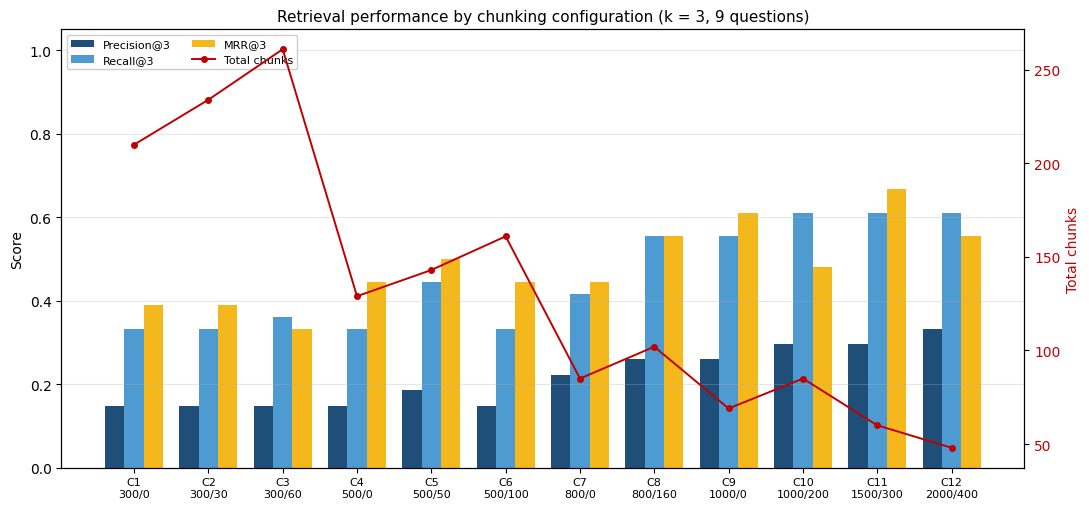

Chart saved: Sagarino_PT-F2_metrics_chart.png


In [20]:
fig, ax = plt.subplots(figsize=(11, 5.2))

x = np.arange(len(table_a))
w = 0.26

ax.bar(x - w, table_a["Precision@3"], w, label="Precision@3", color="#1f4e79")
ax.bar(x,     table_a["Recall@3"],    w, label="Recall@3",    color="#4e9bd1")
ax.bar(x + w, table_a["MRR@3"],       w, label="MRR@3",       color="#f5b81c")

ax.set_xticks(x)
ax.set_xticklabels([f"{r.Config}\n{r.Chunk_Size}/{r.Overlap}" for r in table_a.itertuples()],
                   fontsize=8)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Retrieval performance by chunking configuration "
             f"(k = {TOP_K}, {len(TEST_QUESTIONS)} questions)", fontsize=11)
ax.grid(axis="y", alpha=0.3)

ax2 = ax.twinx()
ax2.plot(x, table_a["Total_Chunks"], color="#c00000", marker="o",
         linewidth=1.4, markersize=4, label="Total chunks")
ax2.set_ylabel("Total chunks", color="#c00000")
ax2.tick_params(axis="y", labelcolor="#c00000")

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, ncol=2, framealpha=0.95)

plt.tight_layout()
plt.savefig("Sagarino_PT-F2_metrics_chart.png", dpi=170)
plt.show()

print("Chart saved: Sagarino_PT-F2_metrics_chart.png")

## 21. Difficulty chart

The same comparison split by difficulty level. Easy questions compress toward the top of the scale
and separate the configurations poorly; the difficult band is where the configurations diverge, and
it is the band the recommendation should be made on.

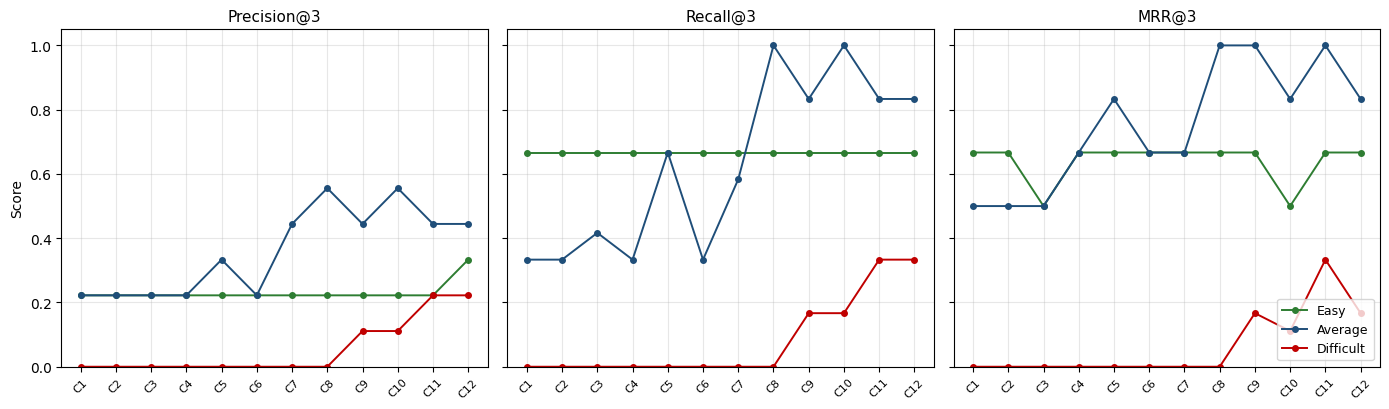

Chart saved: Sagarino_PT-F2_difficulty_chart.png


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)

for ax, metric in zip(axes, ["Precision@3", "Recall@3", "MRR@3"]):
    for d, colour in [("Easy", "#2e7d32"), ("Average", "#1f4e79"), ("Difficult", "#c00000")]:
        sub = table_b[table_b["Difficulty"] == d]
        ax.plot(sub["Config"], sub[metric], marker="o", markersize=4,
                linewidth=1.4, label=d, color=colour)
    ax.set_title(metric, fontsize=11)
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", labelsize=8, rotation=45)
    ax.set_ylim(0, 1.05)

axes[0].set_ylabel("Score")
axes[2].legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig("Sagarino_PT-F2_difficulty_chart.png", dpi=170)
plt.show()

print("Chart saved: Sagarino_PT-F2_difficulty_chart.png")

## 22. Step 7 — the ten analysis questions, answered from the data

Each answer is computed from the tables rather than read off them by eye, so the report cannot
drift from the experiment and a re-run updates every figure.

In [22]:
A = table_a.copy()
B = table_b.copy()

def best(metric):
    row = A.loc[A[metric].idxmax()]
    ties = A[np.isclose(A[metric], row[metric])]["Config"].tolist()
    return row, ties

print("=" * 78)
print("STEP 7 - ANALYSIS")
print("=" * 78)

for n, metric in [(1, "Precision@3"), (2, "Recall@3"), (3, "MRR@3")]:
    row, ties = best(metric)
    print(f"\n{n}. Highest {metric}: {row['Config']} "
          f"({row['Chunk_Size']}/{row['Overlap']}) = {row[metric]:.3f}")
    if len(ties) > 1:
        print(f"   Tied with: {', '.join(c for c in ties if c != row['Config'])}")

print("\n4. Does the winner on one metric hold up on the others?")
for metric in ["Precision@3", "Recall@3", "MRR@3"]:
    row, _ = best(metric)
    ranks = {m: int(A[m].rank(ascending=False, method="min")[row.name]) for m in
             ["Precision@3", "Recall@3", "MRR@3"]}
    print(f"   {row['Config']:<4} best on {metric:<12} -> ranks "
          + ", ".join(f"{m} #{r}" for m, r in ranks.items()))

print("\n5. Best chunk size at a constant overlap percentage")
for pct in sorted(A["Overlap_Pct"].unique()):
    sub = A[A["Overlap_Pct"] == pct]
    if len(sub) < 2:
        continue
    sub = sub.assign(mean3=sub[["Precision@3", "Recall@3", "MRR@3"]].mean(axis=1))
    w = sub.loc[sub["mean3"].idxmax()]
    print(f"   {pct:>5.0f}% overlap, sizes {sorted(sub['Chunk_Size'].tolist())}"
          f" -> best {w['Config']} ({w['Chunk_Size']}) mean of three = {w['mean3']:.3f}")

print("\n6. Effect of increasing overlap at a fixed chunk size")
for size in sorted(A["Chunk_Size"].unique()):
    sub = A[A["Chunk_Size"] == size].sort_values("Overlap")
    if len(sub) < 2:
        continue
    bits = []
    for _, r in sub.iterrows():
        bits.append(f"ovl {int(r['Overlap']):>3} -> {int(r['Total_Chunks']):>3} chunks, "
                    f"R@3 {r['Recall@3']:.3f}, MRR {r['MRR@3']:.3f}")
    print(f"   size {size:>4}: " + "   |   ".join(bits))

print("\n7. Best on the difficult questions (multi-evidence)")
hard = B[B["Difficulty"] == "Difficult"].copy()
hard["mean3"] = hard[["Precision@3", "Recall@3", "MRR@3"]].mean(axis=1)
hw = hard.loc[hard["mean3"].idxmax()]
print(f"   {hw['Config']} ({hw['Chunk_Size']}/{hw['Overlap']}): "
      f"P={hw['Precision@3']:.3f} R={hw['Recall@3']:.3f} MRR={hw['MRR@3']:.3f}")

print("\n8. Did smaller chunks sharpen ranking or fragment the evidence?")
small = A[A["Chunk_Size"] <= 500]
large = A[A["Chunk_Size"] >= 1000]
print(f"   sizes <=500 : MRR@3 {small['MRR@3'].mean():.3f}  Recall@3 {small['Recall@3'].mean():.3f}")
print(f"   sizes >=1000: MRR@3 {large['MRR@3'].mean():.3f}  Recall@3 {large['Recall@3'].mean():.3f}")

print("\n9. Did larger chunks preserve context or add noise?")
print(f"   sizes <=500 : Precision@3 {small['Precision@3'].mean():.3f}")
print(f"   sizes >=1000: Precision@3 {large['Precision@3'].mean():.3f}")

print("\n10. Similar quality at very different cost?")
A2 = A.assign(mean3=A[["Precision@3", "Recall@3", "MRR@3"]].mean(axis=1))
pairs = []
for i in range(len(A2)):
    for j in range(i + 1, len(A2)):
        a, b = A2.iloc[i], A2.iloc[j]
        if abs(a["mean3"] - b["mean3"]) <= 0.02:
            ratio = max(a["Total_Chunks"], b["Total_Chunks"]) / min(a["Total_Chunks"], b["Total_Chunks"])
            if ratio >= 1.5:
                pairs.append((a["Config"], int(a["Total_Chunks"]),
                              b["Config"], int(b["Total_Chunks"]), ratio))
if pairs:
    for ca, na, cb, nb, ratio in sorted(pairs, key=lambda t: -t[4])[:6]:
        print(f"   {ca} ({na} chunks) ~ {cb} ({nb} chunks): {ratio:.1f}x difference in index size")
else:
    print("   No pair within 0.02 of each other differs by 1.5x or more in chunk count.")

STEP 7 - ANALYSIS

1. Highest Precision@3: C12 (2000/400) = 0.333

2. Highest Recall@3: C10 (1000/200) = 0.611
   Tied with: C11, C12

3. Highest MRR@3: C11 (1500/300) = 0.667

4. Does the winner on one metric hold up on the others?
   C12  best on Precision@3  -> ranks Precision@3 #1, Recall@3 #1, MRR@3 #3
   C10  best on Recall@3     -> ranks Precision@3 #2, Recall@3 #1, MRR@3 #6
   C11  best on MRR@3        -> ranks Precision@3 #2, Recall@3 #1, MRR@3 #1

5. Best chunk size at a constant overlap percentage
       0% overlap, sizes [300, 500, 800, 1000] -> best C9 (1000) mean of three = 0.475
      10% overlap, sizes [300, 500] -> best C5 (500) mean of three = 0.377
      20% overlap, sizes [300, 500, 800, 1000, 1500, 2000] -> best C11 (1500) mean of three = 0.525

6. Effect of increasing overlap at a fixed chunk size
   size  300: ovl   0 -> 210 chunks, R@3 0.333, MRR 0.389   |   ovl  30 -> 234 chunks, R@3 0.333, MRR 0.389   |   ovl  60 -> 261 chunks, R@3 0.361, MRR 0.333
   size  50

## 23. Step 8 — the recommendation

Step 8 forbids picking the top value of a single metric. The selection below is made in three
stages, and each one is printed so the reasoning can be checked rather than taken on trust.

1. **Evidence completeness first.** A configuration at which some evidence unit is unreachable is
   set aside, whatever it scores. It cannot answer the questions the corpus was built to answer.
2. **Quality**, as the mean of the three metrics, with the difficult band weighted more heavily,
   since that is the band that separates configurations.
3. **Efficiency as the tie-break.** Where quality is within a small margin, the configuration with
   fewer chunks is preferred, exactly as Step 8 directs.

In [23]:
Q_TOL = 0.02   # quality difference treated as "comparable"

scored = table_a.merge(
    summary[["Config", "Unreachable", "Max_Recall"]], on="Config", how="left")

hard_scores = (table_b[table_b["Difficulty"] == "Difficult"]
               .set_index("Config")[["Precision@3", "Recall@3", "MRR@3"]]
               .mean(axis=1).rename("Hard_Mean"))
scored = scored.merge(hard_scores, on="Config", how="left")

scored["Overall_Mean"] = scored[["Precision@3", "Recall@3", "MRR@3"]].mean(axis=1)
# difficult band carries the extra weight, because it is what separates configurations
scored["Quality"] = (0.6 * scored["Overall_Mean"] + 0.4 * scored["Hard_Mean"]).round(4)

print("=" * 78)
print("STEP 8 - SELECTION")
print("=" * 78)
print(scored[["Config", "Chunk_Size", "Overlap", "Total_Chunks", "Unreachable",
              "Overall_Mean", "Hard_Mean", "Quality"]]
      .sort_values("Quality", ascending=False).round(4).to_string(index=False))

eligible = scored[scored["Unreachable"] == 0]
excluded = scored[scored["Unreachable"] > 0]["Config"].tolist()

print(f"\nStage 1 - evidence completeness")
if excluded:
    print(f"  Excluded for unreachable evidence: {', '.join(excluded)}")
else:
    print("  No configuration loses evidence to chunk boundaries.")

if eligible.empty:
    raise RuntimeError("No configuration retains all evidence units.")

top = eligible["Quality"].max()
near = eligible[eligible["Quality"] >= top - Q_TOL].copy()

print(f"\nStage 2 - quality")
print(f"  Best quality score: {top:.4f}")
print(f"  Within {Q_TOL} of it: {', '.join(near['Config'].tolist())}")

winner = near.sort_values(["Total_Chunks", "Quality"], ascending=[True, False]).iloc[0]

print(f"\nStage 3 - efficiency tie-break")
print(f"  Of those, fewest chunks: {winner['Config']} with {int(winner['Total_Chunks'])}")

print("\n" + "=" * 78)
print("RECOMMENDED CONFIGURATION")
print("=" * 78)
print(f"  {winner['Config']}  -  chunk size {int(winner['Chunk_Size'])} characters, "
      f"overlap {int(winner['Overlap'])} characters "
      f"({winner['Overlap_Pct']:.0f}%)")
print(f"  Precision@3 {winner['Precision@3']:.3f} | Recall@3 {winner['Recall@3']:.3f} "
      f"| MRR@3 {winner['MRR@3']:.3f}")
print(f"  Difficult-question mean {winner['Hard_Mean']:.3f}")
print(f"  {int(winner['Total_Chunks'])} chunks | {winner['Index_KB']:.1f} KB index "
      f"| {winner['Embed_Seconds']:.2f}s to embed | {winner['Mean_Query_ms']:.2f} ms per query")

base = scored[scored["Config"] == BASELINE].iloc[0]
print(f"\n  Part 1 baseline {BASELINE} ({int(base['Chunk_Size'])}/{int(base['Overlap'])}): "
      f"P {base['Precision@3']:.3f} | R {base['Recall@3']:.3f} | MRR {base['MRR@3']:.3f}")
delta = winner["Quality"] - base["Quality"]
if winner["Config"] == BASELINE:
    print("  The baseline is the recommended configuration.")
else:
    print(f"  Change in quality score against the baseline: {delta:+.4f}")

if len(near) > 1:
    print(f"\n  Note: {len(near)} configurations lie within {Q_TOL} of the best quality score, "
          "so\n  the experiment does not establish a decisive winner on quality alone; the "
          "choice\n  above is settled on efficiency, as Step 8 directs.")

scored.to_csv("Sagarino_PT-F2_selection.csv", index=False)
print("\nSaved: Sagarino_PT-F2_selection.csv")

STEP 8 - SELECTION
Config  Chunk_Size  Overlap  Total_Chunks  Unreachable  Overall_Mean  Hard_Mean  Quality
   C11        1500      300            60            0        0.5247     0.2963   0.4333
   C12        2000      400            48            0        0.5000     0.2407   0.3963
    C9        1000        0            69            0        0.4753     0.1482   0.3445
   C10        1000      200            85            0        0.4630     0.1296   0.3296
    C8         800      160           102            0        0.4568     0.0000   0.2741
    C5         500       50           143            0        0.3765     0.0000   0.2259
    C7         800        0            85            2        0.3611     0.0000   0.2167
    C4         500        0           129            2        0.3086     0.0000   0.1852
    C6         500      100           161            0        0.3086     0.0000   0.1852
    C1         300        0           210            3        0.2901     0.0000   0.1741
  

## 24. The guardrail question

G1 is excluded from the metrics because Precision and Recall are undefined when a question has no
relevant evidence. It is run here as a behaviour check: the corpus contains no marketplace refund
window, so no chunk should carry evidence for it at any configuration.

If a chunk were ever marked relevant for G1 it would mean the ground truth is wrong, not that the
system found something.

In [24]:
print("Guardrail:", GUARDRAIL["question"])
print()

chs = create_chunks(pages, 1000, 200)
emb_g = embedder.encode([c["text"] for c in chs], convert_to_numpy=True,
                        normalize_embeddings=True).astype("float32")
idx_g = faiss.IndexFlatIP(EMBED_DIM)
idx_g.add(emb_g)

qv = embedder.encode([GUARDRAIL["question"]], convert_to_numpy=True,
                     normalize_embeddings=True).astype("float32")
sc, ix = idx_g.search(qv, TOP_K)

print(f"{'rank':<6}{'chunk':<8}{'page':<7}{'similarity':<13}{'carries evidence?'}")
for rank, i in enumerate(ix[0], start=1):
    c = chs[int(i)]
    print(f"{rank:<6}{c['chunk_id']:<8}{c['page']:<7}{sc[0][rank-1]:<13.4f}"
          f"{'no - nothing in the corpus answers this'}")

print("\nRetrieval always returns the nearest three chunks; nearness is not relevance.")
print("The refusal is the prompt's responsibility, and Part 1 showed it fires correctly.")

Guardrail: How many days does Shopee give a buyer to request a refund?

rank  chunk   page   similarity   carries evidence?
1     62      12     0.5712       no - nothing in the corpus answers this
2     10      3      0.5152       no - nothing in the corpus answers this
3     61      12     0.5091       no - nothing in the corpus answers this

Retrieval always returns the nearest three chunks; nearness is not relevance.
The refusal is the prompt's responsibility, and Part 1 showed it fires correctly.


## 25. Reproducibility record

Step 9 F asks for the final configuration and the means to reproduce the results. Everything needed
to rebuild this experiment is printed from the live objects, so the record cannot drift from what
was actually run.

In [25]:
record = {
    "dataset": pdf_file,
    "pages_indexed": len(pages),
    "total_characters": int(sum(len(p["text"]) for p in pages)),
    "embedding_model": EMBEDDING_MODEL_NAME,
    "embedding_dim": int(EMBED_DIM),
    "vector_store": "FAISS IndexFlatIP on L2-normalised vectors (cosine)",
    "top_k": TOP_K,
    "questions_scored": len(TEST_QUESTIONS),
    "difficulty_split": {d: sum(1 for q in TEST_QUESTIONS if q["difficulty"] == d)
                         for d in ("Easy", "Average", "Difficult")},
    "evidence_units": int(sum(len(v) for v in EVIDENCE_UNITS.values())),
    "configurations": [{"id": n, "chunk_size": s, "overlap": o} for n, s, o in CONFIGS],
    "baseline": BASELINE,
    "recommended": {
        "config": winner["Config"],
        "chunk_size": int(winner["Chunk_Size"]),
        "overlap": int(winner["Overlap"]),
        "precision_at_3": float(winner["Precision@3"]),
        "recall_at_3": float(winner["Recall@3"]),
        "mrr_at_3": float(winner["MRR@3"]),
        "total_chunks": int(winner["Total_Chunks"]),
    },
    "outputs": [EXCEL_FILE,
                "Sagarino_PT-F2_TableA_configurations.csv",
                "Sagarino_PT-F2_TableB_by_difficulty.csv",
                "Sagarino_PT-F2_TableC_retrieval_log.csv",
                "Sagarino_PT-F2_selection.csv",
                "Sagarino_PT-F2_metrics_chart.png",
                "Sagarino_PT-F2_difficulty_chart.png"],
}

with open("Sagarino_PT-F2_reproducibility.json", "w") as f:
    json.dump(record, f, indent=2)

print("=" * 78)
print("REPRODUCIBILITY RECORD")
print("=" * 78)
print(json.dumps(record, indent=2))
print("\nSaved: Sagarino_PT-F2_reproducibility.json")

REPRODUCIBILITY RECORD
{
  "dataset": "Sagarino_PT-F1_Corpus.pdf",
  "pages_indexed": 17,
  "total_characters": 60860,
  "embedding_model": "all-MiniLM-L6-v2",
  "embedding_dim": 384,
  "vector_store": "FAISS IndexFlatIP on L2-normalised vectors (cosine)",
  "top_k": 3,
  "questions_scored": 9,
  "difficulty_split": {
    "Easy": 3,
    "Average": 3,
    "Difficult": 3
  },
  "evidence_units": 19,
  "configurations": [
    {
      "id": "C1",
      "chunk_size": 300,
      "overlap": 0
    },
    {
      "id": "C2",
      "chunk_size": 300,
      "overlap": 30
    },
    {
      "id": "C3",
      "chunk_size": 300,
      "overlap": 60
    },
    {
      "id": "C4",
      "chunk_size": 500,
      "overlap": 0
    },
    {
      "id": "C5",
      "chunk_size": 500,
      "overlap": 50
    },
    {
      "id": "C6",
      "chunk_size": 500,
      "overlap": 100
    },
    {
      "id": "C7",
      "chunk_size": 800,
      "overlap": 0
    },
    {
      "id": "C8",
      "chunk_size": 800

## 26. Download everything

The files the submission requires: the experiment workbook, the three CSV tables, the selection
table, the two charts, and the reproducibility record.

In [26]:
for f in [EXCEL_FILE,
          "Sagarino_PT-F2_TableA_configurations.csv",
          "Sagarino_PT-F2_TableB_by_difficulty.csv",
          "Sagarino_PT-F2_TableC_retrieval_log.csv",
          "Sagarino_PT-F2_selection.csv",
          "Sagarino_PT-F2_metrics_chart.png",
          "Sagarino_PT-F2_difficulty_chart.png",
          "Sagarino_PT-F2_reproducibility.json"]:
    if os.path.exists(f):
        files.download(f)
        print("downloaded:", f)
    else:
        print("MISSING   :", f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

downloaded: Sagarino_PT-F2_Experiment_Log.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

downloaded: Sagarino_PT-F2_TableA_configurations.csv


... (14 outputs left out)

downloaded: Sagarino_PT-F2_difficulty_chart.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

downloaded: Sagarino_PT-F2_reproducibility.json
